# 05 · A real retention campaign: did the call keep customers?

Part 2 measures what Part 1 cannot: the effect of contacting a customer. KKBox ran no
experiment, so the evidence comes from a randomized retention campaign at a Belgian telecom
operator (Verhelst et al. 2023, OpenML dataset 45580, CC BY-NC-ND 4.0).

11,896 customers judged at high risk of churning, autumn 2020. A random 24% were held back; the
rest were called by the call centre with a retention offer or a tariff recommendation. Churn is
measured over the following two months. The features are anonymized (160 principal components
and 18 coded categories), so this part is about the effect and targeting, not about who churns.

Everything below follows the plan committed before the data was downloaded
([`reports/telecom_analysis_plan.md`](../reports/telecom_analysis_plan.md)).

In [1]:
import os
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "telecom.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import warnings

warnings.filterwarnings("ignore", message=".*penalty.*")   # scikit-learn 1.8+ renames the L1 setting

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src import records
from src.data import telecom
from src.experiment import campaign

df, SOURCE = telecom.load()
PERMUTATIONS = int(os.environ.get("TELECOM_PERMUTATIONS", "1000"))
t, y = df[telecom.TREAT].to_numpy(), df[telecom.OUTCOME].to_numpy()
X = campaign.design(df, telecom.PCS, telecom.FACTORS)
print(f"source: {SOURCE}; {len(df):,} customers, {X.shape[1]} columns after one-hot encoding")

source: real; 11,896 customers, 318 columns after one-hot encoding


## 1. Checks before reading the outcome

**Arm sizes** against the stated 76/24 split, and **randomization**: if the call had gone to a
particular kind of customer, a classifier could predict who was called from the features. A
ridge classifier's cross-validated AUC is compared with its distribution when the treatment
labels are shuffled at random. The plan stops the readout at a permutation p below 0.01.

In [2]:
n1, n0 = int(t.sum()), int((1 - t).sum())
share = n1 / len(t)
data_checks = {"missing_values": int(df[telecom.FEATURES].isna().sum().sum()),
               "duplicate_rows": int(df.duplicated(subset=telecom.FEATURES).sum()),
               "constant_features": [c for c in telecom.FEATURES if df[c].nunique() <= 1]}
rand = campaign.randomization_check(X, t, permutations=PERMUTATIONS)
print(f"called {n1:,} ({share:.2%}), held back {n0:,}; data checks {data_checks}")
print(f"treatment predictable from the features? AUC {rand['auc']:.3f} (95th percentile under random "
      f"labels {rand['null_95th']:.3f}), permutation p = {rand['p_value']:.3f} -> "
      + ("randomization looks sound" if rand["passed"] else "STOP: assignment is predictable"))

called 9,010 (75.74%), held back 2,886; data checks {'missing_values': 0, 'duplicate_rows': 0, 'constant_features': ['FACTOR3']}
treatment predictable from the features? AUC 0.640 (95th percentile under random labels 0.515), permutation p = 0.001 -> STOP: assignment is predictable


The check fails: who was called can be predicted from the profile. The call rate differs by
segment, for example across the levels of one coded category:

In [3]:
by_seg = (df.groupby("FACTOR18", observed=True)[telecom.TREAT].agg(customers="size", share_called="mean")
          .query("customers >= 100").sort_values("customers", ascending=False))
by_seg.round(3)

,customers,share_called
FACTOR18,,
V7,5388,0.829
V4,3375,0.714
V2,2300,0.689
V6,526,0.643
V1,175,0.709


So the held-back group is not a random slice of the called group, and a straight comparison of
churn rates can be biased by who was held back. Following the plan's dated amendment
(written after this check failed, before any adjusted result), the campaign is treated as
**randomized given the features**: each customer's probability of being called (the propensity)
is modelled, and the effect is estimated with a doubly robust estimator that stays unbiased if
either the propensity model or the churn models are right.

## 2. Propensity and overlap

In [4]:
e = campaign.propensity_oof(X, t)
keep = (e >= 0.05) & (e <= 0.95)
print(f"propensity: called {e[t == 1].mean():.2f} on average, held back {e[t == 0].mean():.2f}; "
      f"{(~keep).sum()} customers outside [0.05, 0.95] dropped ({(~keep).mean():.1%})")
Xk, tk, yk, ek = X[keep], t[keep], y[keep], e[keep]
w = campaign.ipw_weights(tk, ek)
smd_raw, smd_w = campaign.weighted_smd(Xk, tk), campaign.weighted_smd(Xk, tk, w)
balance = {"max_smd_before": float(smd_raw.max()), "max_smd_after": float(smd_w.max()),
           "features_over_0_1_before": int((smd_raw > 0.1).sum()), "features_over_0_1_after": int((smd_w > 0.1).sum()),
           "weighted_auc_treatment": float(roc_auc_score(tk, campaign.oof_scores(Xk, tk), sample_weight=w))}
print({k: round(v, 3) if isinstance(v, float) else v for k, v in balance.items()})

propensity: called 0.77 on average, held back 0.71; 276 customers outside [0.05, 0.95] dropped (2.3%)


{'max_smd_before': 0.347, 'max_smd_after': 0.094, 'features_over_0_1_before': 19, 'features_over_0_1_after': 0, 'weighted_auc_treatment': 0.467}


## 3. The effect of the call

In [5]:
mu0, mu1 = campaign.outcome_oof(Xk, tk, yk)
dr = campaign.aipw(tk, yk, ek, mu0, mu1)
ipw = campaign.hajek(tk, yk, ek)
k1, k0 = int(y[t == 1].sum()), int(y[t == 0].sum())
raw = campaign.newcombe(k1, n1, k0, n0)
min_det = campaign.mde(raw.rate_held_back, n1, n0)
held = t == 0
prog = campaign.select_prognostic(X[held], y[held], k=20)
gcomp = campaign.adjusted_effect(X[:, prog], t, y)
table = pd.DataFrame([
    {"estimate": "doubly robust (primary)", "change_pts": dr["diff"] * 100, "lo": dr["ci"][0] * 100, "hi": dr["ci"][1] * 100},
    {"estimate": "inverse-propensity weighted", "change_pts": ipw["diff"] * 100, "lo": ipw["ci"][0] * 100, "hi": ipw["ci"][1] * 100},
    {"estimate": "unadjusted (reference)", "change_pts": raw.diff * 100, "lo": raw.ci[0] * 100, "hi": raw.ci[1] * 100},
    {"estimate": "regression on 20 churn predictors", "change_pts": gcomp["diff"] * 100, "lo": gcomp["ci"][0] * 100,
     "hi": gcomp["ci"][1] * 100}]).set_index("estimate")
print(f"churn: called {raw.rate_called:.2%}, held back {raw.rate_held_back:.2%}; this experiment detects about "
      f"{min_det * 100:.2f} points with 80% power")
table.round(2)

churn: called 3.36%, held back 3.64%; this experiment detects about 1.12 points with 80% power


,change_pts,lo,hi
estimate,,,
doubly robust (primary),-0.49,-1.49,0.51
inverse-propensity weighted,-0.38,-1.40,0.56
unadjusted (reference),-0.28,-1.10,0.46
regression on 20 churn predictors,-0.42,-1.22,0.30


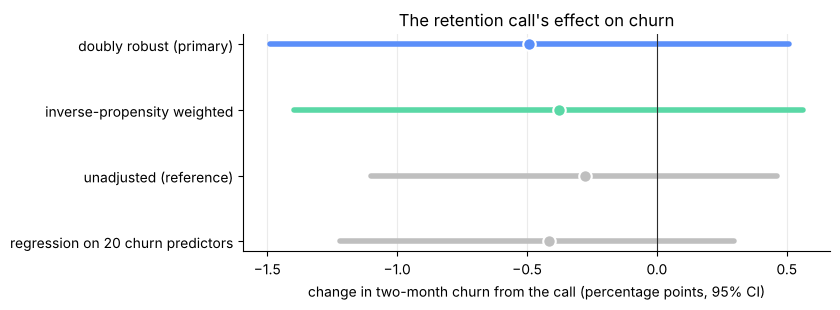

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.2))
cols = ["#5B8FF9", "#5AD8A6", "#BFBFBF", "#BFBFBF"]
for i, (lab, r) in enumerate(table.iterrows()):
    ax.plot([r.lo, r.hi], [i, i], color=cols[i], lw=4, solid_capstyle="round")
    ax.plot(r.change_pts, i, "o", color=cols[i], ms=9, mec="white", mew=1.5)
ax.axvline(0, color="#2B2B2B", lw=0.8)
ax.set_yticks(range(len(table)), table.index)
ax.invert_yaxis()
ax.set(xlabel="change in two-month churn from the call (percentage points, 95% CI)",
       title="The retention call's effect on churn")
ax.grid(alpha=0.25, axis="x")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "05_campaign_effect.png", SOURCE)

In [7]:
np.save(telecom.cache_dir(SOURCE) / "propensity.npy", e)   # reused by notebook 06; never committed
record = {"n": len(df), "called": n1, "held_back": n0, "share_called": share, "data_checks": data_checks,
          "randomization": rand, "call_rate_by_factor18": by_seg["share_called"].to_dict(),
          "propensity_dropped": int((~keep).sum()), "balance": balance,
          "effect_aipw": dr, "effect_ipw": ipw, "effect_unadjusted": raw.as_dict(), "effect_gcomp_20": gcomp,
          "mde_80": min_det}
print("wrote", records.write("05_campaign_effect", record, SOURCE).name)
lines = [
    ("The campaign was not randomized the same way for everyone: the profile predicts who was called "
     if not rand["passed"] else "The randomization check passes: the profile does not predict who was called ")
    + f"(AUC {rand['auc']:.2f}, permutation p = {rand['p_value']:.3f}).",
    f"After weighting by the propensity, the largest feature imbalance falls from {balance['max_smd_before']:.2f} "
    f"to {balance['max_smd_after']:.2f} standard deviations.",
    f"Doubly robust effect of the call: {dr['diff'] * 100:+.2f} points of two-month churn, 95% CI "
    f"[{dr['ci'][0] * 100:+.2f}, {dr['ci'][1] * 100:+.2f}]; the unadjusted comparison gives {raw.diff * 100:+.2f}.",
    ("No detectable effect" if dr["ci"][0] < 0 < dr["ci"][1] else "A detectable effect")
    + f"; the data rule out a reduction larger than {-dr['ci'][0] * 100:.1f} points "
    f"({-dr['ci'][0] / raw.rate_held_back:.0%} of the held-back churn rate).",
]
print("\n".join(f"{i}. {s}" for i, s in enumerate(lines, 1)))

wrote 05_campaign_effect.json
1. The campaign was not randomized the same way for everyone: the profile predicts who was called (AUC 0.64, permutation p = 0.001).
2. After weighting by the propensity, the largest feature imbalance falls from 0.35 to 0.09 standard deviations.
3. Doubly robust effect of the call: -0.49 points of two-month churn, 95% CI [-1.49, +0.51]; the unadjusted comparison gives -0.28.
4. No detectable effect; the data rule out a reduction larger than 1.5 points (41% of the held-back churn rate).
